# 1. Data exploration

Audit training and validation data before changing the model; deployment samples are assessed only in Notebook 3. Each record contains one synchronized image from each camera, the current robot state, and an eight-step future action chunk; it is not a video or complete episode. The deployment windows are introduced in notebook 3 and contain independent samples rather than continuous episode timelines. Use the starter cells below to become familiar with the record structure; extend or replace them as needed.

**Scope:** Only the frozen training and validation splits are analyzed in this notebook. Statistical baselines are fitted exclusively on training labels and evaluated on validation labels. The action endpoint statistic below is explicitly a final-step XYZ error, not necessarily the official endpoint metric.

In [1]:
from ml_project.data import make_default_datasets
from ml_project.drift import dataset_frame

full_datasets = make_default_datasets(
    train_size=512,
    validation_size=128,
    deployment_size=128,
)

train_frame = dataset_frame(full_datasets["train"])
val_frame = dataset_frame(full_datasets["validation"])

print("Training:", len(train_frame))
print("Validation:", len(val_frame))

print("\nCamera availability:")
for name, df in [("Train", train_frame), ("Validation", val_frame)]:
    print(name)
    print(df[["front_available", "wrist_available"]].mean())

print("\nAction label availability:")
print(train_frame["label_available"].value_counts(dropna=False))

Training: 512
Validation: 128

Camera availability:
Train
front_available    1.0
wrist_available    1.0
dtype: float64
Validation
front_available    1.0
wrist_available    1.0
dtype: float64

Action label availability:
label_available
True    512
Name: count, dtype: int64


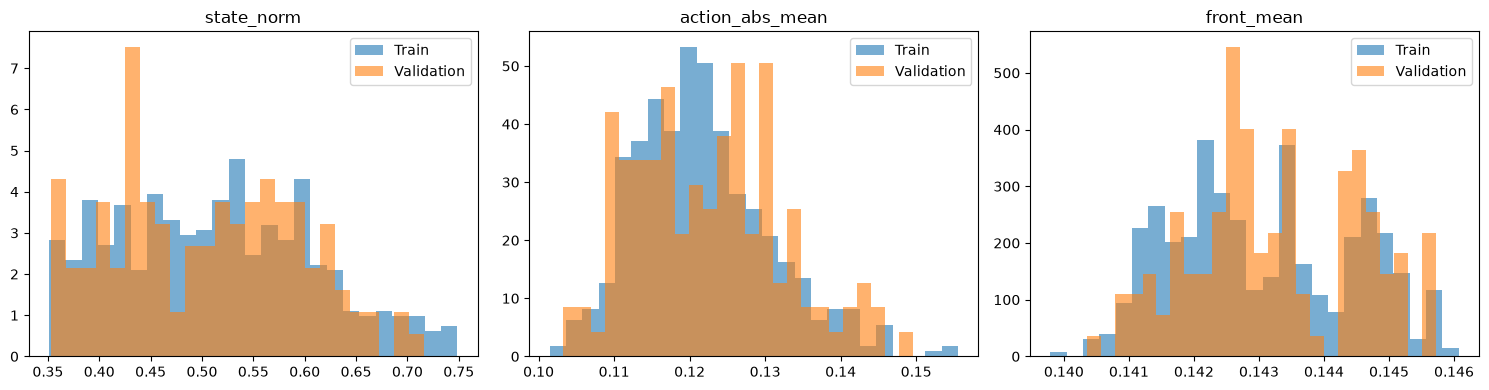

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(
    axes,
    ["state_norm", "action_abs_mean", "front_mean"],
    strict=True,
):
    ax.hist(train_frame[column].dropna(), bins=25, alpha=0.6, density=True, label="Train")
    ax.hist(val_frame[column].dropna(), bins=25, alpha=0.6, density=True, label="Validation")
    ax.set_title(column)
    ax.legend()

plt.tight_layout()
plt.show()

In [7]:
print("Duplicate sample IDs:")
print("Train:", train_frame["sample_id"].duplicated().sum())
print("Validation:", val_frame["sample_id"].duplicated().sum())

overlap = set(train_frame["sample_id"]) & set(val_frame["sample_id"])
print("Cross-split sample ID overlap:", len(overlap))

print("\nTraining task distribution:")
print(train_frame["task"].value_counts())

print("\nValidation task distribution:")
print(val_frame["task"].value_counts())

print("\nTarget/destination combinations:")
print(pd.crosstab(train_frame["target_color"], train_frame["destination_color"]))

print("Available splits:", list(full_datasets.keys()))
print("Training samples:", len(full_datasets["train"]))
print("Validation samples:", len(full_datasets["validation"]))

sample = full_datasets["train"][0]
print("\nSample keys:", list(sample.keys()))
print("Instruction:", sample["prompt"])
print("Robot state:", sample["state"])
print("Actions shape:", sample["actions"].shape)

print("\nDataset columns:")
print(train_frame.columns.tolist())

print("\nMissing values:")
print(train_frame.isna().sum())

Duplicate sample IDs:
Train: 0
Validation: 0
Cross-split sample ID overlap: 0

Training task distribution:
task
yellow_to_green    56
blue_to_yellow     51
red_to_blue        49
yellow_to_red      46
green_to_red       44
red_to_green       42
red_to_yellow      40
green_to_yellow    39
blue_to_green      39
green_to_blue      39
blue_to_red        35
yellow_to_blue     32
Name: count, dtype: int64

Validation task distribution:
task
yellow_to_red      16
green_to_blue      16
green_to_yellow    16
red_to_blue        14
blue_to_yellow     13
yellow_to_green    10
yellow_to_blue      9
blue_to_green       9
blue_to_red         9
red_to_yellow       6
red_to_green        6
green_to_red        4
Name: count, dtype: int64

Target/destination combinations:
destination_color  blue  green  red  yellow
target_color                               
blue                  0     39   35      51
green                39      0   44      39
red                  49     42    0      40
yellow            

### Exploratory Data Analysis — Findings

The dataset contains 512 training samples and 128 validation samples. Each observation includes a language instruction, two camera views (front and wrist), a seven-dimensional robot state, and an eight-step action sequence with seven action dimensions per step.

**Data completeness:** All training and validation samples have both camera views available. All 512 training samples have action labels. No duplicate sample identifiers were found within the training or validation splits, and no sample identifiers overlap across these splits.

**Task distribution:** The training set contains all 12 possible source/destination combinations among four colors, excluding same-color pairs. Individual task frequencies range from 32 to 56 samples. The validation set also covers all 12 combinations, but frequencies range from 4 to 16, suggesting that aggregate validation metrics should be complemented by task-level analysis.

**Feature distributions:** Training and validation histograms for robot-state magnitude, mean absolute action magnitude, and front-camera mean intensity show substantial overlap. No obvious large distribution shift is visible in these scalar features, although this does not rule out differences in object placement, visual content, or task difficulty.

**Camera observations:** Both camera views contain task-relevant objects, with different projected positions. This motivates evaluating whether multi-camera fusion provides benefits over single-camera inputs.

**Limitations:** The dataset consists of observation-action samples rather than complete closed-loop rollouts. Offline action prediction error should not be interpreted as robotic task success. Distinct sample IDs also do not rule out leakage from correlated observations or shared trajectories.

## Additional analysis: action structure and strong statistical controls

**Purpose.** Determine how much of the action-chunk variance is explained by a shared action prior, task identity, or robot state. All statistical predictors are fitted **only on the training split**. Each record is an independent observation–action pair; the eight action steps are within-record predictions, not a continuous episode across rows.

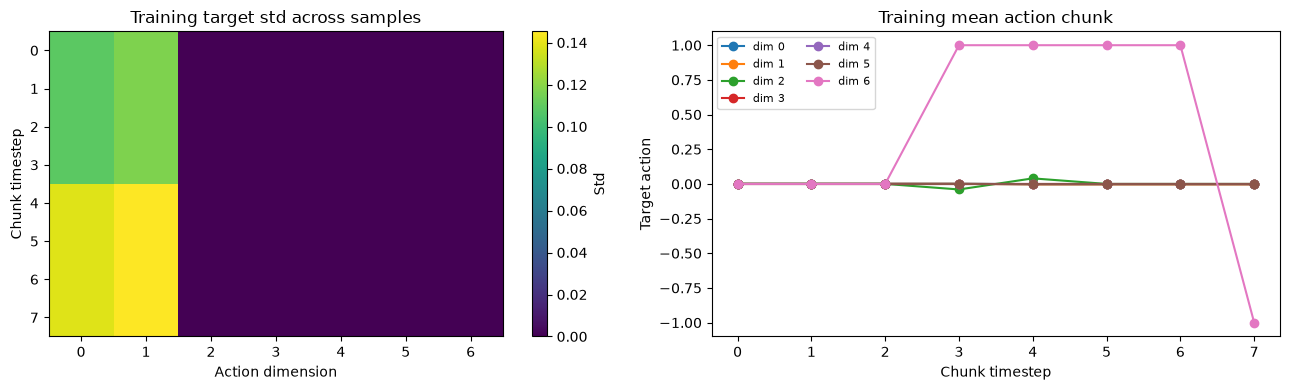

Across-sample std of per-chunk mean by dimension:


,std
dim_0,0.057825
dim_1,0.058740
dim_2,0.000000
dim_3,0.000000
dim_4,0.000000
dim_5,0.000000
dim_6,0.000000


Note: zero variation in chunk means does not imply zero within-chunk variation.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Use the full frozen splits created above; only labeled examples enter action statistics.
def labeled_arrays(dataset):
    examples = [dataset[i] for i in range(len(dataset)) if bool(dataset[i]["action_mask"])]
    actions = np.stack([np.asarray(s["actions"], dtype=np.float64) for s in examples])
    states = np.stack([np.asarray(s["state"], dtype=np.float64) for s in examples])
    tasks = np.asarray([str(s["metadata"]["task"]) for s in examples])
    return actions, states, tasks


train_actions, train_states, train_tasks = labeled_arrays(full_datasets["train"])
val_actions, val_states, val_tasks = labeled_arrays(full_datasets["validation"])
assert train_actions.shape[1:] == (8, 7)

mean_chunk = train_actions.mean(axis=0)
std_chunk = train_actions.std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(std_chunk, aspect="auto", cmap="viridis")
axes[0].set(
    title="Training target std across samples",
    xlabel="Action dimension",
    ylabel="Chunk timestep",
    xticks=range(7),
    yticks=range(8),
)
fig.colorbar(im, ax=axes[0], label="Std")
for d in range(7):
    axes[1].plot(range(8), mean_chunk[:, d], marker="o", label=f"dim {d}")
axes[1].set(title="Training mean action chunk", xlabel="Chunk timestep", ylabel="Target action")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

print("Across-sample std of per-chunk mean by dimension:")
display(
    pd.Series(
        train_actions.mean(axis=1).std(axis=0), index=[f"dim_{d}" for d in range(7)]
    ).to_frame("std")
)
print("Note: zero variation in chunk means does not imply zero within-chunk variation.")

### Train-fitted baselines: global mean, task mean, and state-only ridge

Ridge regression uses a standardized seven-dimensional state with an intercept and L2 regularization; the action target is flattened to 56 outputs. These are diagnostic controls, not replacement robot policies. Do not fit or tune on deployment labels.

In [10]:
from pathlib import Path

# Fit only on train. Standardization parameters are estimated on training states.
state_mu = train_states.mean(axis=0)
state_sd = train_states.std(axis=0)
state_sd[state_sd < 1e-8] = 1.0
x_train = (train_states - state_mu) / state_sd
x_val = (val_states - state_mu) / state_sd
Y = train_actions.reshape(len(train_actions), -1)
alpha = 1.0
X = np.column_stack([np.ones(len(x_train)), x_train])
penalty = np.diag([0.0] + [alpha] * x_train.shape[1])
ridge_coef = np.linalg.solve(X.T @ X + penalty, X.T @ Y)

task_means = {
    task: train_actions[train_tasks == task].mean(axis=0) for task in np.unique(train_tasks)
}


def statistical_predictions(states, tasks):
    n = len(states)
    global_pred = np.broadcast_to(mean_chunk, (n, 8, 7)).copy()
    task_pred = np.stack([task_means.get(task, mean_chunk) for task in tasks])
    standardized = (states - state_mu) / state_sd
    state_pred = (np.column_stack([np.ones(n), standardized]) @ ridge_coef).reshape(n, 8, 7)
    return {"global_mean": global_pred, "task_mean": task_pred, "state_ridge": state_pred}


def baseline_metrics(targets, predictions):
    delta = predictions - targets
    return {
        "mse": float(np.mean(delta**2)),
        "motion_mse_0_5": float(np.mean(delta[:, :, :6] ** 2)),
        "dim6_mse": float(np.mean(delta[:, :, 6] ** 2)),
        "endpoint_error_xyz": float(np.linalg.norm(delta[:, -1, :3], axis=1).mean()),
    }


rows = []
for split in ("validation",):
    y, states, tasks = labeled_arrays(full_datasets[split])
    for model_name, pred in statistical_predictions(states, tasks).items():
        rows.append(
            {"split": split, "model": model_name, "n_labeled": len(y), **baseline_metrics(y, pred)}
        )
statistical_results = pd.DataFrame(rows)
display(statistical_results.round(6))
# Endpoint definition above is explicitly XYZ at the final chunk step; compare to
# other scripts only if they use the same definition.


repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir()), None)
if repo_root is None:
    raise FileNotFoundError("Cannot find repository results directory")
eda_out = repo_root / "results" / "eda"
eda_out.mkdir(parents=True, exist_ok=True)
statistical_results.to_csv(eda_out / "statistical_baselines.csv", index=False)

,split,model,n_labeled,mse,motion_mse_0_5,dim6_mse,endpoint_error_xyz
0,validation,global_mean,128,0.004931,0.005753,0.0,0.195393
1,validation,task_mean,128,0.005009,0.005843,0.0,0.196304
2,validation,state_ridge,128,0.004085,0.004766,0.0,0.195416


### What to conclude

Compare the unconditional mean with the multimodal VLA **before** attributing gains to vision or language. If task means do not outperform the global mean, the labels provide little incremental signal to a task-only predictor. A state ridge advantage establishes a predictive association with state, but does not establish causality. Camera pixels can contain task information even when an offline policy learns to ignore it. Interpret these alongside the fixed-seed modality-shuffling diagnostics; aggregate MSE sensitivity alone is not proof that predictions are unchanged.